# 03. Extended Analysis
Saxlanmış final modelin davranışı: sabitlik, drift, lift, inam intervalları, xəta analizi, interpretasiya, zamana görə CV.
Model `models/model.joblib`-dən yüklənir (02-ni yenidən işlətməyə ehtiyac yoxdur).

## 1. Setup

In [1]:
# Kitabxanalar və layihə sabitləri (aylar, xərc fərziyyələri src/config.py-dədir)
import gc, json, warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import roc_curve

from src.config import *
from src.evaluation import score_report, operating_point
from src.features import BAFCleaner

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

## 2. Data və Model Yükləmə

In [3]:
# Datanı və 02-də saxlanmış final modeli yükləyirik; model kalibrə olunmuş pipeline-dır
df = pd.read_csv(DATA_PATH)
model = joblib.load("models/model.joblib")                      # kalibrə olunmuş final model
meta = json.loads(Path("models/meta.json").read_text(encoding="utf-8"))
THRESHOLD = meta["threshold"]
inner = model.calibrated_classifiers_[0].estimator.estimator    # Calibrated -> Frozen -> Pipeline

X, y = df.drop(columns=[TARGET]), df[TARGET]
p_all = model.predict_proba(X)[:, 1]                            # bütün sətirlər üçün kalibrə olunmuş ehtimal
is_test = df[TIME_COL].isin(TEST_MONTHS).values
X_te, y_te, p_te = X[is_test], y[is_test], p_all[is_test]
print(f"Model: {meta['model']} | threshold={THRESHOLD:.4f} | test sətirləri: {is_test.sum():,}")

Model: HistGradientBoosting | threshold=0.0199 | test sətirləri: 205,011


## 3. Aylar üzrə Sabitlik
Ay 0-4 modelin öyrəndiyi aylardır (in-sample), 5 valid, 6-7 test. Threshold zamanla eyni davranırmı?

In [4]:
# Hər ay üçün metrikləri və seçilən threshold-da nəticəni hesablayırıq (model zamanla sabitdirmi?)
rows = []
for m in sorted(df[TIME_COL].unique()):
    idx = (df[TIME_COL] == m).values
    s = score_report(y[idx], p_all[idx])
    o = operating_point(y[idx], p_all[idx], THRESHOLD, COST_FN, COST_FP)
    split = "train" if m in TRAIN_MONTHS else ("valid" if m in VALID_MONTHS else "test")
    rows.append({"month": m, "split": split, "fraud_rate": y[idx].mean(), **s,
                 "recall@thr": o["recall"], "flag_rate": o["flag_rate"], "cost_per_1000": o["cost_per_1000"]})
by_month = pd.DataFrame(rows).set_index("month")
by_month.round(4)

,split,fraud_rate,pr_auc,roc_auc,tpr_at_5pct_fpr,recall@thr,flag_rate,cost_per_1000
month,,,,,,,,
0,train,0.0113,0.1521,0.8918,0.4873,0.8353,0.2207,3044.4730
1,train,0.0094,0.1380,0.9059,0.4866,0.8230,0.1849,2602.8052
2,train,0.0087,0.1421,0.9061,0.4875,0.8038,0.1677,2464.7574
3,train,0.0092,0.1606,0.9253,0.6085,0.8894,0.2023,2451.0389
4,train,0.0114,0.1778,0.9221,0.5847,0.9001,0.2182,2647.5633
5,valid,0.0118,0.1833,0.8991,0.4649,0.7916,0.1685,2823.6803
6,test,0.0134,0.1630,0.8930,0.4759,0.8172,0.1932,3047.1119
7,test,0.0147,0.1980,0.8962,0.4671,0.7794,0.1595,3106.1615


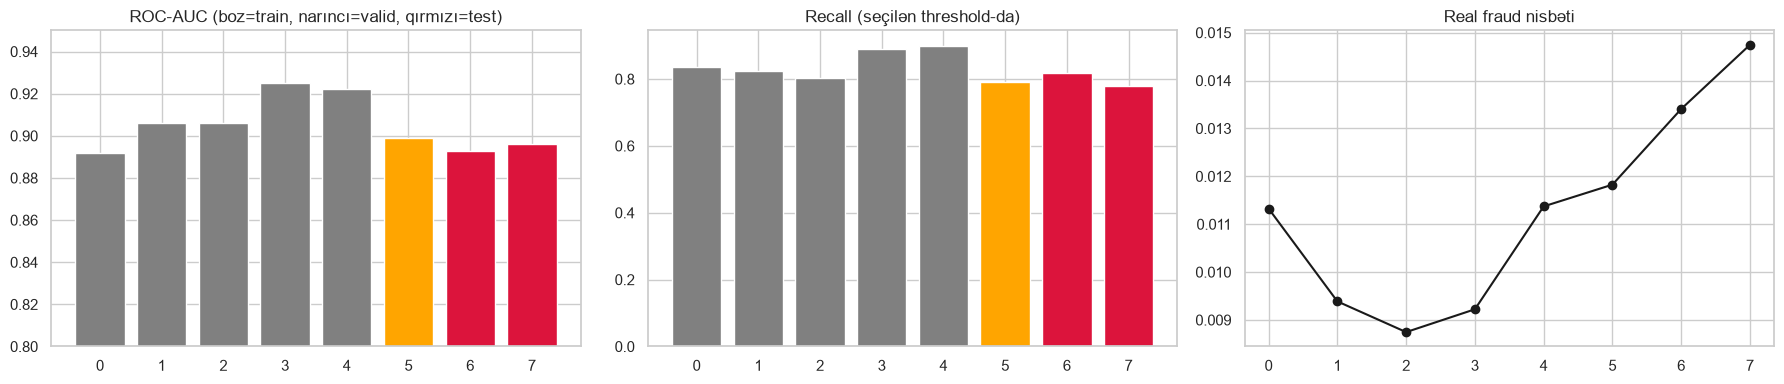

In [5]:
# Aylıq ROC-AUC, recall və real fraud nisbəti (rəng: train / valid / test)
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
colors = by_month["split"].map({"train": "gray", "valid": "orange", "test": "crimson"})
ax[0].bar(by_month.index, by_month["roc_auc"], color=colors); ax[0].set(ylim=(0.8, 0.95), title="ROC-AUC (boz=train, narıncı=valid, qırmızı=test)")
ax[1].bar(by_month.index, by_month["recall@thr"], color=colors); ax[1].set(title="Recall (seçilən threshold-da)")
ax[2].plot(by_month.index, by_month["fraud_rate"], marker="o", c="k"); ax[2].set(title="Real fraud nisbəti")
plt.tight_layout(); plt.show()

## 4. Data Drift (PSI)
Population Stability Index: train (ay 0-4) vs test (ay 6-7). Praktik qayda: <0.1 sabit, 0.1-0.25 orta, >0.25 güclü dəyişmə.

In [6]:
# PSI: train ilə test paylanması arasında fərq. <0.1 sabit, 0.1-0.25 orta, >0.25 güclü dəyişmə
def psi(expected: pd.Series, actual: pd.Series, bins: int = 10) -> float:
    """PSI: expected (train) və actual (test) paylanmaları arasında fərq (NaN ayrıca qrup)."""
    eps = 1e-6
    if expected.dtype == object or str(expected.dtype).startswith(("str", "category")):
        cats = sorted(set(expected.dropna()) | set(actual.dropna()))
        e = expected.value_counts(normalize=True).reindex(cats, fill_value=0) + eps
        a = actual.value_counts(normalize=True).reindex(cats, fill_value=0) + eps
    else:
        edges = np.unique(np.quantile(expected.dropna(), np.linspace(0, 1, bins + 1)))
        edges[0], edges[-1] = -np.inf, np.inf
        e = np.append(np.histogram(expected.dropna(), edges)[0], expected.isna().sum()) / len(expected) + eps
        a = np.append(np.histogram(actual.dropna(), edges)[0], actual.isna().sum()) / len(actual) + eps
    return float(np.sum((np.asarray(a) - np.asarray(e)) * np.log(np.asarray(a) / np.asarray(e))))

Xc = BAFCleaner(drop_cols=[TIME_COL]).transform(X)     # -1 → NaN (drift düzgün ölçülsün)
tr_mask = df[TIME_COL].isin(TRAIN_MONTHS).values
psi_tbl = pd.Series({col: psi(Xc.loc[tr_mask, col], Xc.loc[is_test, col]) for col in Xc.columns if Xc[col].nunique() > 1})
psi_tbl = psi_tbl.sort_values(ascending=False)
Xc_te = Xc[is_test].copy()                              # xəta analizi üçün yalnız test hissəsi
score_psi = psi(pd.Series(p_all[tr_mask]), pd.Series(p_te))
print(f"Model skorunun PSI-si (train vs test): {score_psi:.3f}")
del Xc                                                 # yaddaşı azaltmaq üçün (1M sətirlik surət)
gc.collect()
psi_tbl.head(10).round(4).to_frame("psi")

Model skorunun PSI-si (train vs test): 0.014


,psi
velocity_4w,3.7386
velocity_24h,1.8918
velocity_6h,1.0886
zip_count_4w,0.4909
date_of_birth_distinct_emails_4w,0.3988
credit_risk_score,0.2612
income,0.0787
proposed_credit_limit,0.0705
session_length_in_minutes,0.0626
name_email_similarity,0.0438


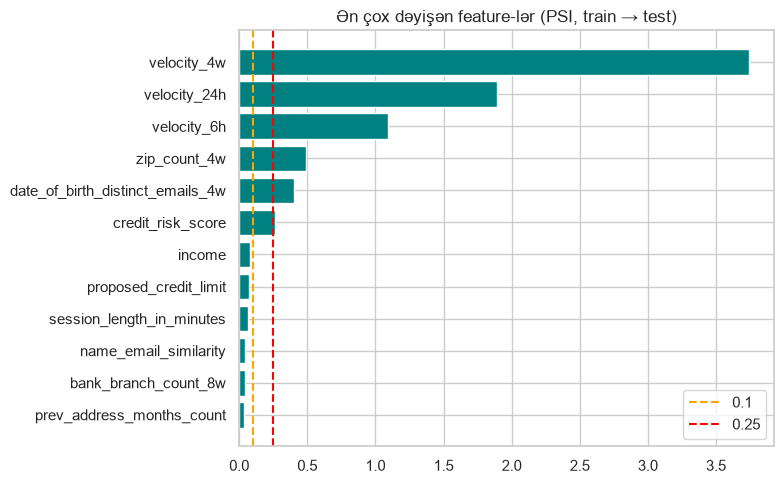

In [7]:
# Ən çox dəyişən feature-lər və PSI hədləri (0.1, 0.25)
top = psi_tbl.head(12)[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top.index, top.values, color="teal")
plt.axvline(0.1, c="orange", ls="--", label="0.1"); plt.axvline(0.25, c="red", ls="--", label="0.25")
plt.title("Ən çox dəyişən feature-lər (PSI, train → test)"); plt.legend(); plt.tight_layout(); plt.show()

## 5. Lift, Gain, KS
Skorlar azalan sırada 10 qrupa bölünür. Birinci decile fraudu baza nisbətindən neçə dəfə çox tutur?

In [8]:
# Gains cədvəli: skora görə decile-lərə bölüb lift və kumulyativ recall hesablayırıq; KS = max(TPR - FPR)
def gains_table(y_true, p, n_bins: int = 10) -> pd.DataFrame:
    """Skorları azalan sırada n_bins qrupa bölür: fraud faizi, lift, kumulyativ recall."""
    d = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(p)}).sort_values("p", ascending=False).reset_index(drop=True)
    d["decile"] = pd.qcut(d.index, n_bins, labels=False) + 1
    g = d.groupby("decile").agg(n=("y", "size"), frauds=("y", "sum"), min_score=("p", "min"))
    g["fraud_rate"] = g["frauds"] / g["n"]
    g["lift"] = g["fraud_rate"] / d["y"].mean()
    g["cum_recall"] = g["frauds"].cumsum() / d["y"].sum()
    return g

gt = gains_table(y_te, p_te)
fpr, tpr, _ = roc_curve(y_te, p_te)
print(f"KS statistikası (test): {np.max(tpr - fpr):.3f}")
gt.round(4)

KS statistikası (test): 0.635


,n,frauds,min_score,fraud_rate,lift,cum_recall
decile,,,,,,
1,20502,1925,0.0289,0.0939,6.6884,0.6689
2,20501,455,0.0142,0.0222,1.5810,0.8270
3,20501,180,0.0064,0.0088,0.6254,0.8895
4,20501,133,0.0037,0.0065,0.4621,0.9357
5,20501,66,0.0027,0.0032,0.2293,0.9587
6,20501,48,0.0014,0.0023,0.1668,0.9753
7,20501,32,0.0006,0.0016,0.1112,0.9864
8,20501,17,0.0002,0.0008,0.0591,0.9924
9,20501,16,0.0001,0.0008,0.0556,0.9979


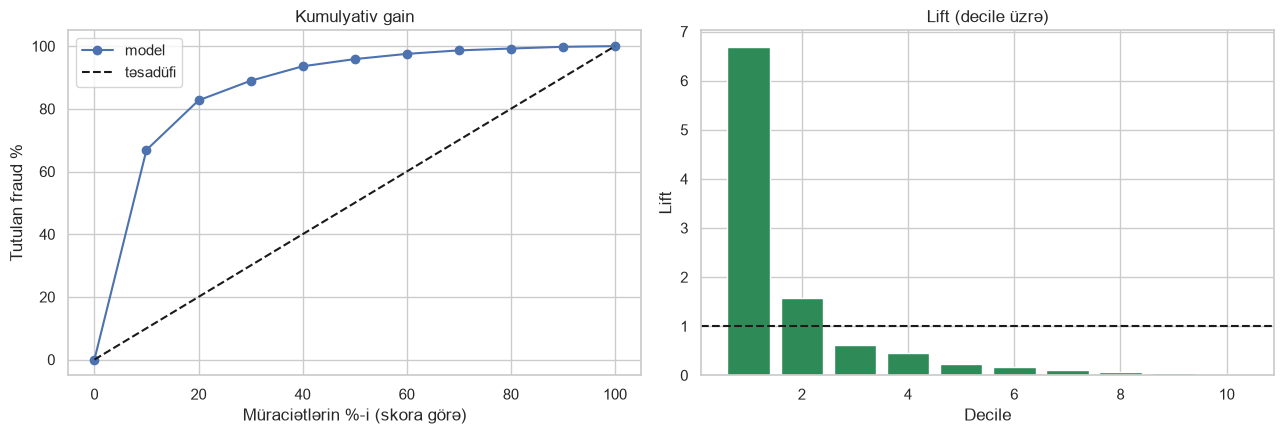

In [9]:
# Kumulyativ gain və lift qrafikləri
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(np.arange(0, 101, 10), np.r_[0, gt["cum_recall"].values * 100], marker="o", label="model")
ax[0].plot([0, 100], [0, 100], "k--", label="təsadüfi"); ax[0].set(xlabel="Müraciətlərin %-i (skora görə)", ylabel="Tutulan fraud %", title="Kumulyativ gain"); ax[0].legend()
ax[1].bar(gt.index, gt["lift"], color="seagreen"); ax[1].axhline(1, c="k", ls="--"); ax[1].set(xlabel="Decile", ylabel="Lift", title="Lift (decile üzrə)")
plt.tight_layout(); plt.show()

## 6. Bootstrap İnam İntervalları
Final test metrikaları nə qədər dəqiqdir? 200 bootstrap nümunəsi.

In [10]:
# Bootstrap: test nümunəsini təkrar seçib metrikaların 95% inam intervalını tapırıq
def bootstrap_ci(y_true, p, n_boot: int = 200, seed: int = RANDOM_STATE) -> pd.DataFrame:
    """PR-AUC, ROC-AUC, TPR@5%FPR üçün nöqtə qiyməti və 95% bootstrap inam intervalı."""
    rng = np.random.default_rng(seed)
    y_arr, p_arr = np.asarray(y_true), np.asarray(p)
    draws = {k: [] for k in ["pr_auc", "roc_auc", "tpr_at_5pct_fpr"]}
    for _ in range(n_boot):
        i = rng.integers(0, len(y_arr), len(y_arr))
        s = score_report(y_arr[i], p_arr[i])
        for k in draws:
            draws[k].append(s[k])
    point = score_report(y_arr, p_arr)
    return pd.DataFrame({k: {"point": point[k], "ci_low": np.percentile(v, 2.5), "ci_high": np.percentile(v, 97.5)}
                         for k, v in draws.items()}).T

bootstrap_ci(y_te, p_te).round(4)

,point,ci_low,ci_high
pr_auc,0.1768,0.1644,0.1911
roc_auc,0.8938,0.8876,0.9003
tpr_at_5pct_fpr,0.4715,0.4542,0.4896


## 7. Xəta Analizi
Tutulan fraud (TP), qaçan fraud (FN), yanlış alarm (FP) və düzgün legit (TN) qruplarının profilləri.

In [11]:
# Xəta analizi: TP/FN/FP/TN qruplarının orta profilini müqayisə edirik (təsviri, səbəb sübutu deyil)
pred = p_te >= THRESHOLD
group = np.where(y_te == 1, np.where(pred, "TP", "FN"), np.where(pred, "FP", "TN"))
profile_cols = ["name_email_similarity", "current_address_months_count", "proposed_credit_limit", "credit_risk_score",
                "device_distinct_emails_8w", "income", "velocity_6h", "bank_branch_count_8w", "customer_age", "prev_address_months_count_missing"]
prof = Xc_te[profile_cols].groupby(group).mean().T[["TP", "FN", "FP", "TN"]]
print("Qrup ölçüləri:", pd.Series(group).value_counts().to_dict())
prof.round(3)

Qrup ölçüləri: {'TN': 168092, 'FP': 34041, 'TP': 2298, 'FN': 580}


,TP,FN,FP,TN
name_email_similarity,0.366,0.448,0.397,0.490
current_address_months_count,115.439,87.776,113.317,74.172
proposed_credit_limit,880.474,506.276,696.250,428.262
credit_risk_score,199.101,145.221,179.823,137.609
device_distinct_emails_8w,1.057,1.014,1.031,1.004
income,0.745,0.676,0.709,0.603
velocity_6h,3549.637,3851.750,3658.877,3821.724
bank_branch_count_8w,96.165,119.705,120.572,165.846
customer_age,41.658,34.224,39.192,32.579
prev_address_months_count_missing,0.946,0.766,0.926,0.657


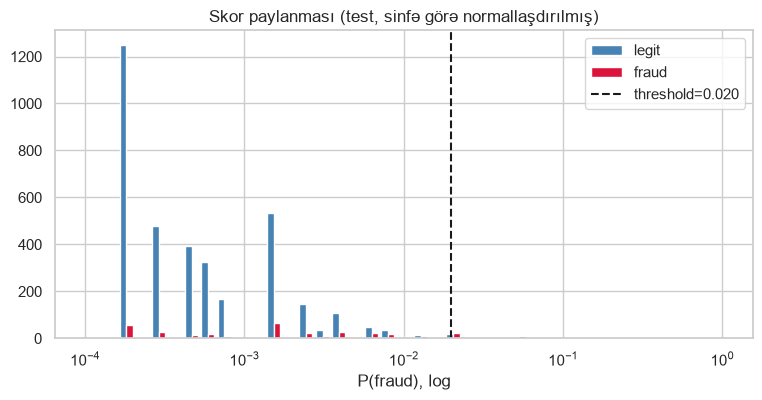

In [12]:
# Skor paylanması (log şkala) və threshold xətti
plt.figure(figsize=(9, 4))
plt.hist([p_te[y_te == 0], p_te[y_te == 1]], bins=np.logspace(-4, 0, 40), label=["legit", "fraud"], color=["steelblue", "crimson"], density=True)
plt.xscale("log"); plt.axvline(THRESHOLD, c="k", ls="--", label=f"threshold={THRESHOLD:.3f}")
plt.xlabel("P(fraud), log"); plt.title("Skor paylanması (test, sinfə görə normallaşdırılmış)"); plt.legend(); plt.show()

## 8. İnterpretasiya: Partial Dependence
Bir feature dəyişəndə orta kalibrə olunmuş fraud ehtimalı necə dəyişir (qalan feature-lər real qalır, 5000 test sətri).

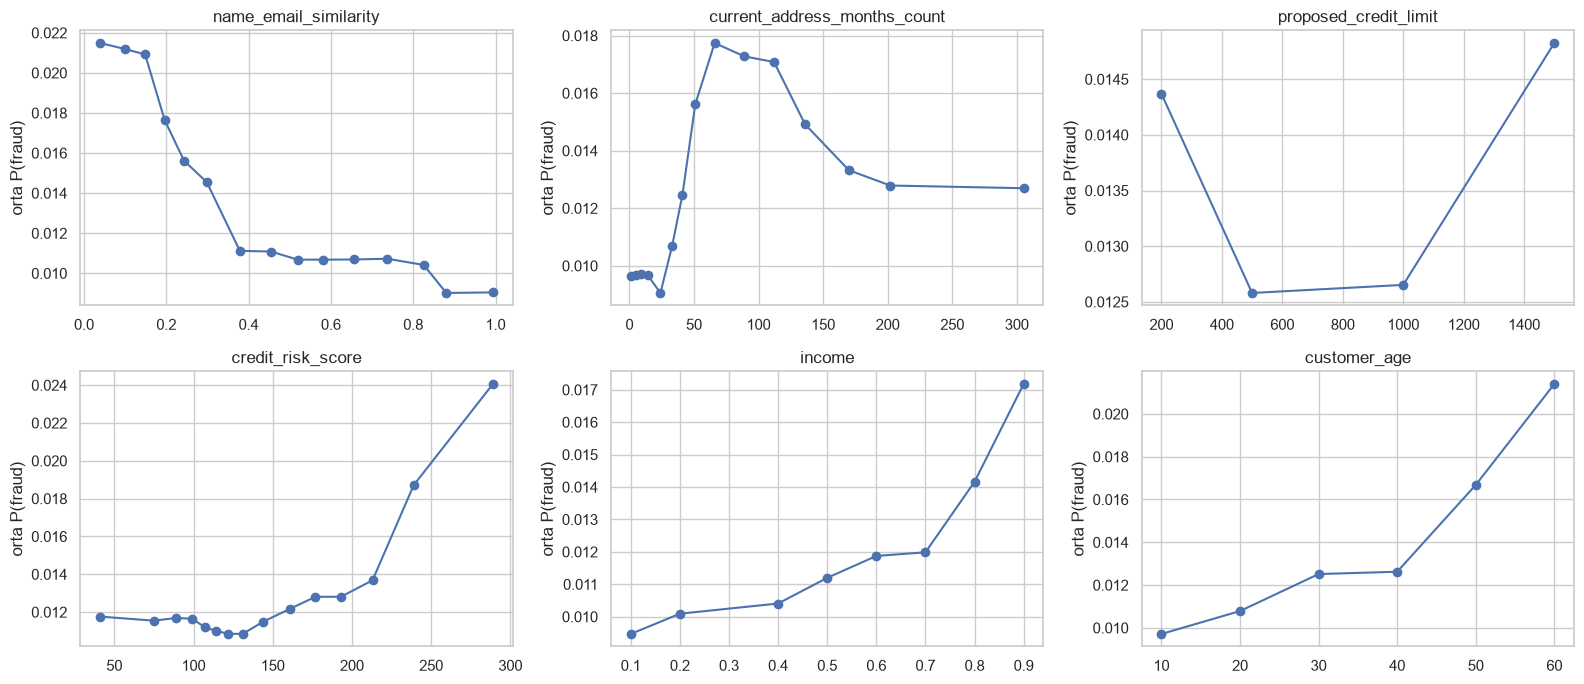

In [13]:
# Partial dependence: bir feature-i dəyişib qalanını sabit saxlayaraq orta ehtimalın necə dəyişdiyini ölçürük
def partial_dependence_raw(mdl, X_sample: pd.DataFrame, col: str, n_grid: int = 15):
    """col-u qrid dəyərlərinə təyin edib orta fraud ehtimalını qaytarır (xam vahidlərdə)."""
    s = X_sample[col]
    s = s[s >= 0] if col in MISSING_MINUS1 else s              # -1 'yoxdur' kodudur, qridə düşməsin
    grid = np.unique(np.quantile(s, np.linspace(0.02, 0.98, n_grid)))
    vals = []
    for v in grid:
        Xv = X_sample.copy()
        Xv[col] = v
        vals.append(mdl.predict_proba(Xv)[:, 1].mean())
    return grid, np.array(vals)

pdp_sample = X_te.sample(5000, random_state=RANDOM_STATE)
pdp_cols = ["name_email_similarity", "current_address_months_count", "proposed_credit_limit",
            "credit_risk_score", "income", "customer_age"]
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.ravel(), pdp_cols):
    g, v = partial_dependence_raw(model, pdp_sample, col)
    ax.plot(g, v, marker="o"); ax.set_title(col); ax.set_ylabel("orta P(fraud)")
plt.tight_layout(); plt.show()

## 9. Zamana Görə Cross-Validation (expanding window)
Hər fold-da keçmiş aylarda öyrənib növbəti ayı proqnozlaşdırırıq. Tək split nəticəsinin təsadüf olmadığını yoxlayır.

In [14]:
# Genişlənən pəncərə ilə zamana görə CV: hər fold-da keçmiş aylarla öyrədib növbəti ayda yoxlayırıq (sızıntı yoxdur)
cv_rows = []
for k in range(3, 8):
    tr_m = (df[TIME_COL] < k).values
    va_m = (df[TIME_COL] == k).values
    fold_pipe = clone(inner).fit(X[tr_m], y[tr_m])                # final pipeline-ın parametrləri ilə
    s = score_report(y[va_m], fold_pipe.predict_proba(X[va_m])[:, 1])
    cv_rows.append({"train_months": f"0-{k - 1}", "val_month": k, "fraud_rate": y[va_m].mean(), **s})
cv = pd.DataFrame(cv_rows)
print(cv[["pr_auc", "roc_auc", "tpr_at_5pct_fpr"]].agg(["mean", "std"]).round(4))
cv.round(4)

      pr_auc  roc_auc  tpr_at_5pct_fpr
mean  0.1858   0.9020           0.5512
std   0.0209   0.0084           0.0250


,train_months,val_month,fraud_rate,pr_auc,roc_auc,tpr_at_5pct_fpr
0,0-2,3,0.0092,0.1591,0.9115,0.5647
1,0-3,4,0.0114,0.1808,0.9105,0.5730
2,0-4,5,0.0118,0.1913,0.8972,0.5400
3,0-5,6,0.0134,0.1808,0.8937,0.5124
4,0-6,7,0.0147,0.2168,0.8971,0.5658


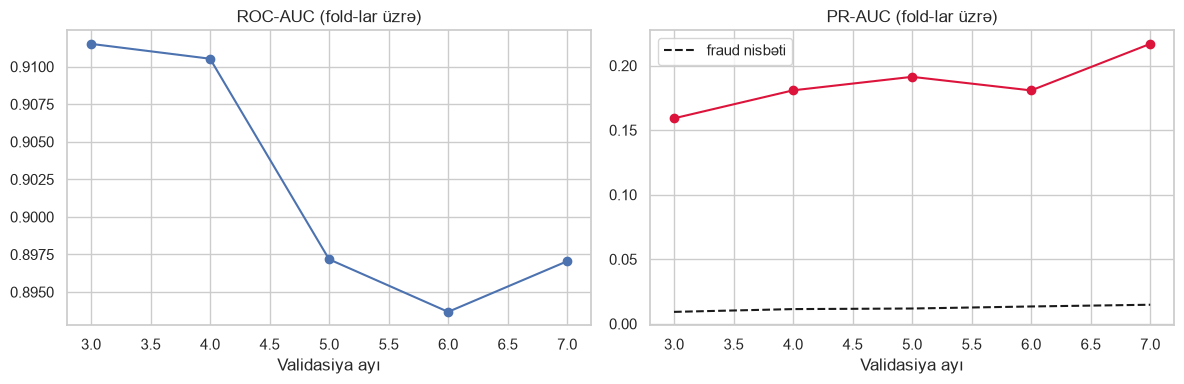

In [15]:
# Fold-lar üzrə ROC-AUC və PR-AUC (qırıq xətt: həmin ayın fraud nisbəti)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(cv["val_month"], cv["roc_auc"], marker="o"); ax[0].set(title="ROC-AUC (fold-lar üzrə)", xlabel="Validasiya ayı")
ax[1].plot(cv["val_month"], cv["pr_auc"], marker="o", c="crimson"); ax[1].plot(cv["val_month"], cv["fraud_rate"], ls="--", c="k", label="fraud nisbəti")
ax[1].set(title="PR-AUC (fold-lar üzrə)", xlabel="Validasiya ayı"); ax[1].legend()
plt.tight_layout(); plt.show()

## 10. Nəticə
Bütün rəqəmlər yuxarıdakı cədvəllərdədir; şərhləri `DEFENSE_QA.md`-də.